# 02. Baseline'ы: случайный и по популярности

Данные получены в: `src/prepare_interactions.py`
Код оценки лежит в `src/evaluate.py`, здесь только запуск, таблицы и графики.

Оцениваем на **val**: тест оставляем нетронутым до финального сравнения.

## Загрузка

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path("..") / "src"))  # код проекта лежит в src/
import evaluate as ev

table, catalog = ev.load_interactions()
cases = ev.build_cases(table, "val") # для каждого val-пользователя пара «что он уже знает (`seen`)» и «что спрятано (`targets`)»

len(cases), len(catalog)

(173, 6198)

## Запуск baseline'ов

- `random`: случайный порядок кандидатов.
- `popularity`: кандидаты по убыванию числа train-пользователей, досмотревших аниме. Для всех пользователей одинаковый порядок, различаются только исключённые уже виденные.

Для каждого пользователя кандидаты — каталог без его `*_input`. Метрики усредняются по пользователям.

In [2]:
rankers = {
    "random": ev.make_random_ranker(),
    "popularity": ev.make_popularity_ranker(ev.popularity_scores(table)),
}
results = pd.DataFrame({name: ev.evaluate(r, cases, catalog) for name, r in rankers.items()})
results.round(4)

,random,popularity
recall@10,0.0031,0.1071
recall@20,0.0049,0.1680
hit_rate@10,0.0636,0.7977
hit_rate@20,0.1329,0.8728
ndcg@10,0.0108,0.3140
ndcg@20,0.0108,0.2886
coverage@10,0.2452,0.0095
coverage@20,0.4308,0.0165
users,173.0000,173.0000


Как читать:

- `recall@k`: какая доля спрятанных позитивов оказалась в первых k.
- `hit_rate@k`: у какой доли пользователей нашёлся хотя бы один спрятанный позитив.
- `ndcg@k`: то же, но выше позиция — больше вклад.
- `coverage@k`: какая доля каталога вообще попала в чьи-то топ-k. Маленькое значение значит, что система показывает всем одно и то же.

## Шум случайного baseline'а

Случайный ранжер зависит от `seed`. Запустим с пятью разными, чтобы увидеть, насколько метрика «плавает» только из-за случайности.

In [3]:
random_runs = pd.DataFrame(
    [ev.evaluate(ev.make_random_ranker(seed), cases, catalog) for seed in range(5)]
)
random_runs[["recall@10", "hit_rate@10", "ndcg@10"]].agg(["mean", "std"]).round(4)

,recall@10,hit_rate@10,ndcg@10
mean,0.0020,0.0694,0.0072
std,0.0007,0.0041,0.0006


## Сравнение на графике

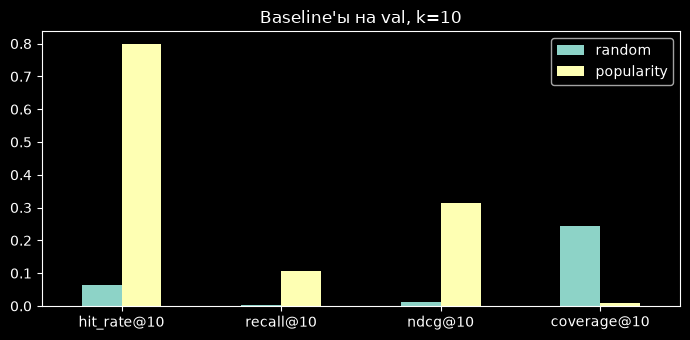

In [4]:
metrics = ["hit_rate@10", "recall@10", "ndcg@10", "coverage@10"]
results.loc[metrics].plot.bar(figsize=(7, 3.5), rot=0)
plt.title("Baseline'ы на val, k=10")
plt.tight_layout()

Вывод:

Мы видим, что отбор по популярности работает очень хорошо, у 80% пользователей среди первых 10 аниме есть хотя бы одно, которое он хотел бы посмотреть. Так и смотря на NDCG = 0.31 популярность выдаёт нужные аниме высоко в списке.

По всем метрикам случайность не находит почти ничего.

Следующие модели нужно сравнивать с популярностью по паре «точность и покрытие», а не только по точности. На val 173 пользователя, малые разницы между моделями могут быть шумом.

Попробуем следующие требования к модели: точность не ниже 90% от метрик популярности и покрытие должно быть хотя бы в 10 раз больше

То есть модель удачна, если ndcg@10 ≥ 0,283 и coverage@10 ≥ 0,095. Две оговорки, которые я тоже записала:

Важно:
- На val 173 человека, и разница в 10% точности лежит в пределах шума. Решать надо по доверительным интервалам, а не по одному числу.
- Покрытие на val не может быть выше 0,279 (173 человека × 10 мест на 6198 аниме), так что сравнивать можно только на одной и той же выборке.